# Cassava Leaf Disease Classification Using Traditional Machine Learning and Deep Learning

## Problem statement and motivation

Cassava is an important food and income crop, and diseases can reduce yields and threaten food security. Identifying disease symptoms from leaf images could help farmers and agricultural workers screen plants more consistently, although an image classifier is a decision-support tool rather than a replacement for expert diagnosis. Prior research has demonstrated the use of deep learning for image-based cassava disease detection [1]. This project compares handcrafted-feature machine-learning models with custom CNNs and ImageNet-pretrained MobileNetV2 and EfficientNetB0 models, using the same stratified train/validation/test split. EfficientNet provides a parameter-efficient approach to scaling CNNs [2], while MobileNetV2 is designed for efficient image recognition [3].

### Key links

1. [Cassava Leaf Disease Classification dataset and competition (Kaggle)](https://www.kaggle.com/competitions/cassava-leaf-disease-classification)
2. [EfficientNet paper — Tan and Le (2019)](https://proceedings.mlr.press/v97/tan19a.html)
3. [MobileNetV2 paper — Sandler et al. (2018)](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html)

### References

[1] M. Ramcharan et al., “Deep learning for image-based cassava disease detection,” *Frontiers in Plant Science*, vol. 8, 2017. [https://doi.org/10.3389/fpls.2017.01852](https://doi.org/10.3389/fpls.2017.01852)

[2] M. Tan and Q. V. Le, “EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks,” *Proceedings of the 36th International Conference on Machine Learning*, 2019. [https://proceedings.mlr.press/v97/tan19a.html](https://proceedings.mlr.press/v97/tan19a.html)

[3] M. Sandler et al., “MobileNetV2: Inverted Residuals and Linear Bottlenecks,” *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition*, 2018. [https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html](https://openaccess.thecvf.com/content_cvpr_2018/html/Sandler_MobileNetV2_Inverted_Residuals_CVPR_2018_paper.html)

---


In [2]:
# Colab only: install the few packages that are not preinstalled
!pip install -q scikit-image kaggle tqdm

## Importing Libraries and Configuring the Experiment Environment

In [1]:
import os, sys, io, json, glob, time, shutil, hashlib, warnings, itertools, subprocess
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import MobileNetV2, EfficientNetB0
from tensorboard.plugins.hparams import api as hp

from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, PredefinedSplit, learning_curve
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, average_precision_score)
warnings.filterwarnings("ignore", category=UserWarning)

# ----------------------------- configuration -----------------------------
IN_COLAB   = "google.colab" in sys.modules
SEED       = 42
QUICK_RUN  = False        # True = tiny debug run on a subset. NEVER report results from a quick run.
QUICK_FRAC = 0.08         # fraction of the data used when QUICK_RUN is True
USE_PRETRAINED = True     # ImageNet weights (needs internet); False only for offline code tests
IMG_SIZE   = 224          # all images are resized once to IMG_SIZE x IMG_SIZE (cache below)
BATCH_SIZE = 32
EPOCH_SCALE = 1.0         # multiply all epoch budgets (e.g. 0.5 to halve training time)
AUTOTUNE   = tf.data.AUTOTUNE

BASE      = "/content/cassava_dataset"                    # raw Kaggle files (temporary Colab disk)
CACHE_DIR = f"/content/cassava_cache_{IMG_SIZE}"          # resized copies (temporary Colab disk)
OUT_DIR   = "/content/drive/MyDrive/cassava_project" if IN_COLAB else "./outputs"   # persistent outputs
if QUICK_RUN:
    OUT_DIR += "_QUICKRUN"
LOG_ROOT  = os.path.join(OUT_DIR, "tensorboard")
MODEL_DIR = os.path.join(OUT_DIR, "models")
FIG_DIR   = os.path.join(OUT_DIR, "figures")
HIST_DIR  = os.path.join(OUT_DIR, "histories")
PRED_DIR  = os.path.join(OUT_DIR, "predictions")
FEAT_FILE = os.path.join(OUT_DIR, f"handcrafted_features_{IMG_SIZE}.npz")
RESULTS_CSV = os.path.join(OUT_DIR, "results_table.csv")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
for d in (OUT_DIR, LOG_ROOT, MODEL_DIR, FIG_DIR, HIST_DIR, PRED_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

keras.utils.set_random_seed(SEED)          # seeds Python, NumPy and TensorFlow
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
print("Outputs go to:", OUT_DIR)
if QUICK_RUN:
    print("\n" + "!" * 70 + "\n QUICK_RUN IS ON: results are for debugging only, do not report them.\n" + "!" * 70)

Mounted at /content/drive
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Outputs go to: /content/drive/MyDrive/cassava_project


## 2. Data acquisition

The data come from the Kaggle competition *cassava-leaf-disease-classification*. Before the first download you must (1) accept the competition rules on Kaggle and (2) store your Kaggle API token in **Colab Secrets** (key icon in the left sidebar) under the name `KAGGLE_API_TOKEN` and switch on "Notebook access".


In [3]:
CLASS_FILE = f"{BASE}/label_num_to_disease_map.json"

def setup_kaggle_token():
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("KAGGLE_API_TOKEN")
    except Exception:
        token = os.environ.get("KAGGLE_API_TOKEN")
    assert token, "Add KAGGLE_API_TOKEN to Colab Secrets (left sidebar, key icon) and enable notebook access."
    os.environ["KAGGLE_API_TOKEN"] = token
    path = os.path.expanduser("~/.kaggle/access_token")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w") as f:
        f.write(token)
    os.chmod(path, 0o600)

def download_and_extract():
    os.makedirs(BASE, exist_ok=True)
    zip_path = f"{BASE}/cassava-leaf-disease-classification.zip"
    if not os.path.exists(zip_path):
        setup_kaggle_token()
        subprocess.run(["kaggle", "competitions", "download", "-c", "cassava-leaf-disease-classification", "-p", BASE], check=True)
    print("Extracting (about 6 GB, a few minutes)...")
    subprocess.run(["unzip", "-q", "-o", zip_path, "-d", BASE], check=True)

if not os.path.exists(f"{BASE}/train.csv"):
    download_and_extract()
else:
    print("Dataset already extracted.")

raw_df = pd.read_csv(f"{BASE}/train.csv")
with open(CLASS_FILE) as f:
    CLASS_MAP = {int(k): v for k, v in json.load(f).items()}
CLASS_NAMES = [CLASS_MAP[i] for i in range(len(CLASS_MAP))]
N_CLASSES = len(CLASS_NAMES)

# ---- integrity check: every labelled image must exist --------------------------------
def find_missing():
    return [f for f in raw_df.image_id if not os.path.exists(f"{BASE}/train_images/{f}")]
missing = find_missing()
if missing:
    print(f"{len(missing)} of {len(raw_df)} images are missing: extracting the zip file again...")
    download_and_extract()
    missing = find_missing()
assert not missing, f"{len(missing)} images are still missing: delete {BASE} and run this cell again to download a fresh copy."

print(f"Raw samples: {len(raw_df):,}  (project requirement: at least 20,000)")
if not QUICK_RUN:
    assert len(raw_df) >= 20000, "dataset smaller than the 20,000-sample requirement"
else:
    raw_df = raw_df.groupby("label", group_keys=False).sample(frac=QUICK_FRAC, random_state=SEED).reset_index(drop=True)
    print(f"QUICK_RUN: using only {len(raw_df):,} images")

Extracting (about 6 GB, a few minutes)...
Raw samples: 21,397  (project requirement: at least 20,000)


## 3. Exploratory data analysis

The EDA checks the five-class label distribution and samples image aspect ratios before modelling. CMD is the dominant class (13,158 images; 61.49%), while CBB is the smallest class (1,087; 5.08%), making the majority class about 12.1 times as large as the minority class. An always-CMD classifier would therefore reach about 61.5% accuracy without recognising any other disease; macro-F1 and per-class recall are needed to assess whether a model distinguishes the minority classes. The aspect-ratio histogram checks whether images have broadly consistent shapes before they are resized to the model input size.

,class,images,share_%
0,Cassava Bacterial Blight (CBB),1087,5.08
1,Cassava Brown Streak Disease (CBSD),2189,10.23
2,Cassava Green Mottle (CGM),2386,11.15
3,Cassava Mosaic Disease (CMD),13158,61.49
4,Healthy,2577,12.04


Imbalance ratio (largest / smallest class): 12.1
Accuracy of always predicting the majority class: 0.615  <- the baseline any model must beat


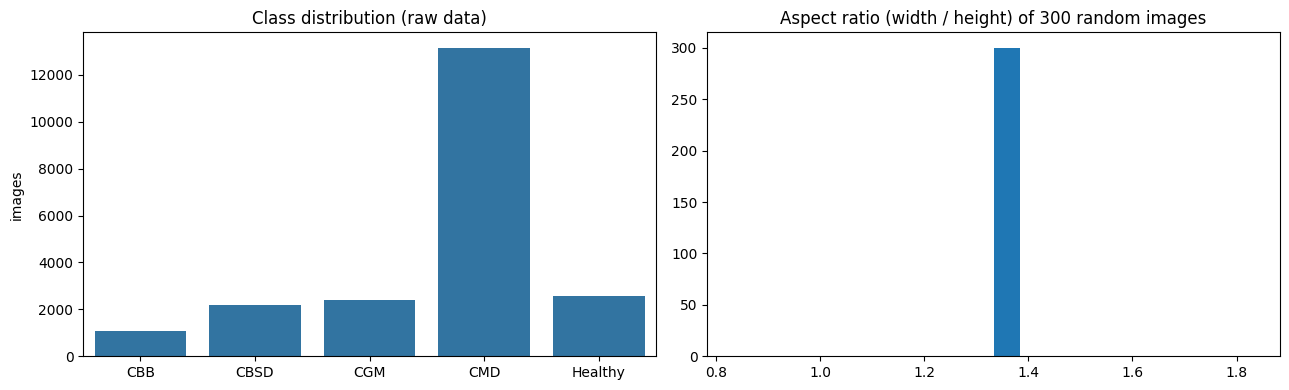

Most common image size: {(800, 600): 300}


In [5]:
counts = raw_df.label.value_counts().sort_index()
eda = pd.DataFrame({"class": CLASS_NAMES, "images": counts.values, "share_%": (100 * counts.values / counts.sum()).round(2)})
display(eda)
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")
print(f"Accuracy of always predicting the majority class: {counts.max() / counts.sum():.3f}  <- the baseline any model must beat")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=[n.split("(")[-1].strip(")") if "(" in n else n for n in CLASS_NAMES], y=counts.values, ax=ax[0])
ax[0].set_title("Class distribution (raw data)"); ax[0].set_ylabel("images")
sizes = [Image.open(f"{BASE}/train_images/{f}").size for f in raw_df.image_id.sample(min(300, len(raw_df)), random_state=SEED)]
ax[1].hist([w / h for w, h in sizes], bins=20); ax[1].set_title("Aspect ratio (width / height) of 300 random images")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_class_distribution.png", dpi=150); plt.show()
print("Most common image size:", pd.Series(sizes).value_counts().head(3).to_dict())

### Interpretation of the Dataset Overview

The dataset contains **21,397 cassava leaf images** across five classes. Cassava Mosaic Disease (CMD) is the dominant class with 13,158 images (61.49%), while Cassava Bacterial Blight (CBB) has only 1,087 images (5.08%). The largest class is about **12.1 times** the size of the smallest. Therefore, a model could achieve approximately 61.5% accuracy by always predicting CMD, without learning to distinguish the diseases.

For this reason, accuracy alone is not sufficient. **Macro-F1** is used as the main comparison metric because it gives each class equal weight. The images also vary in appearance, so the sample grid should be reviewed for differences in symptoms, lighting, backgrounds, and visual similarity between classes.


## Visualising Sample Images from Each Class

The grid shows four randomly selected examples from each class using the fixed seed, so the same examples can be reproduced. Comparing rows helps identify visible differences and overlap in leaf colour, mottling, lesions, lighting, and background. Some symptoms can look similar across classes, and field backgrounds may distract a model; these examples are useful for visual inspection but cannot establish that any individual label is correct.

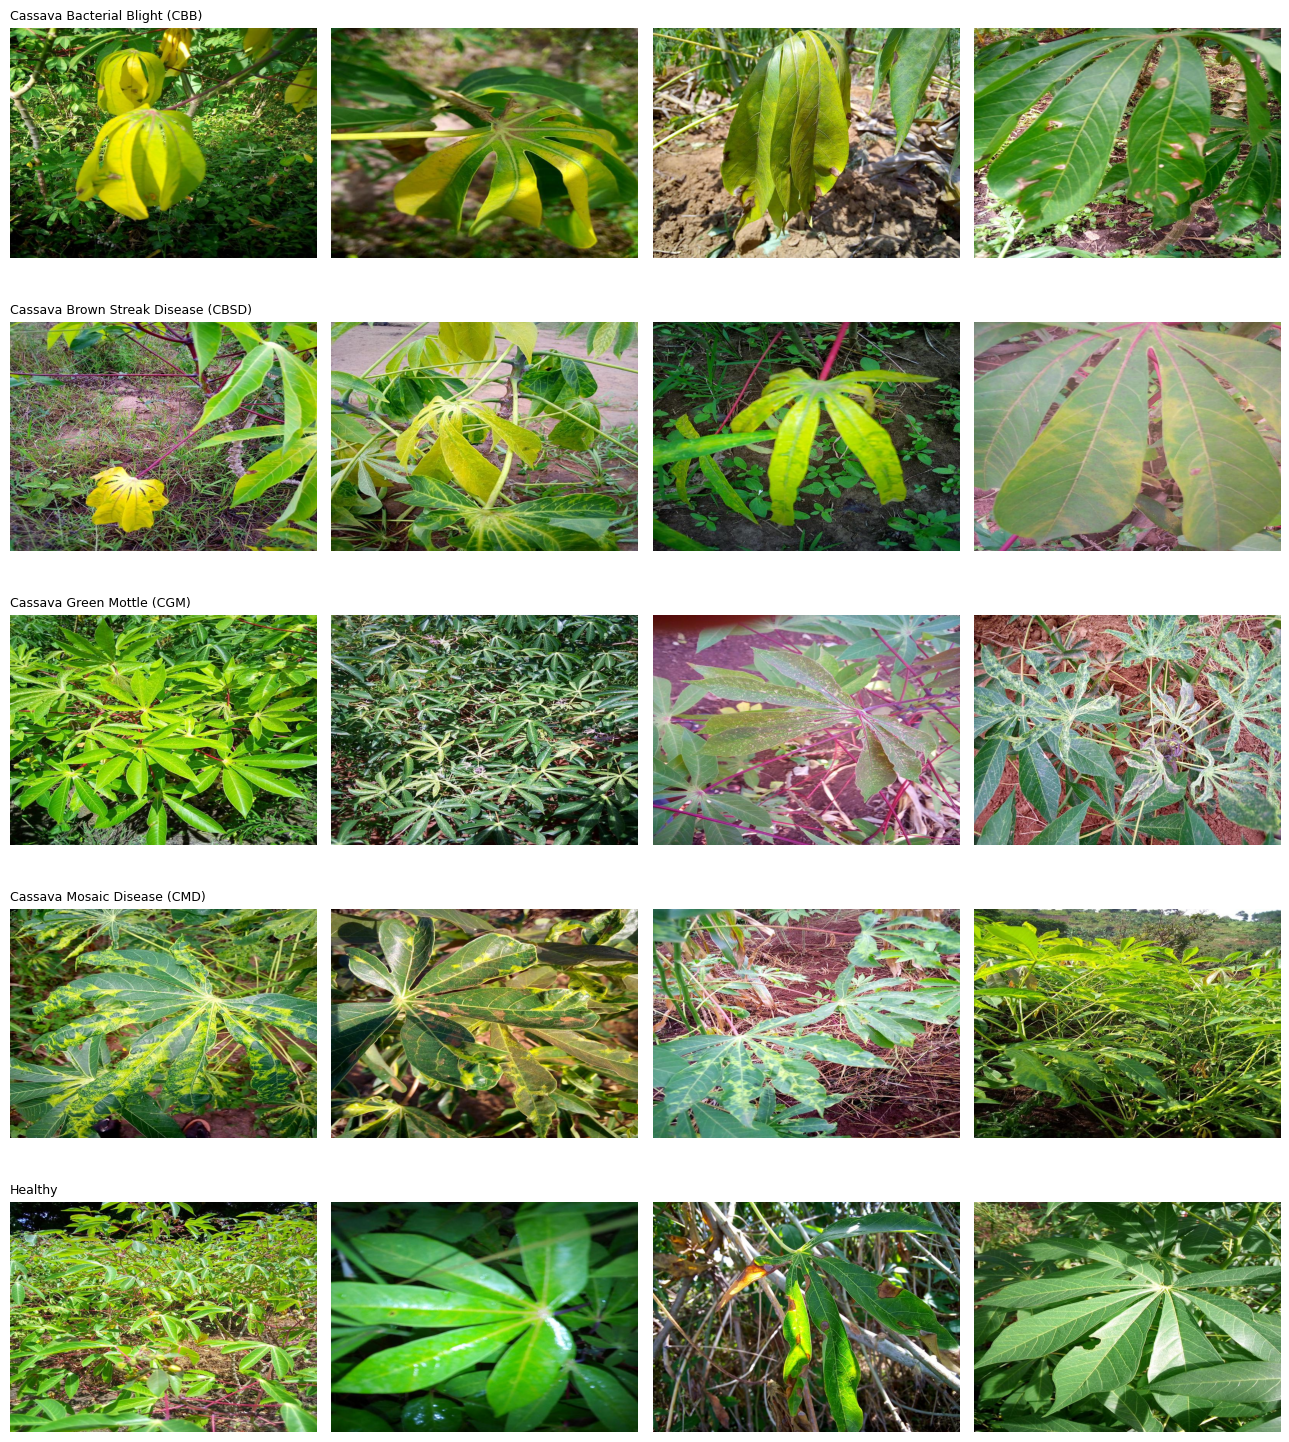

In [6]:
fig, axes = plt.subplots(N_CLASSES, 4, figsize=(13, 3 * N_CLASSES))
for c in range(N_CLASSES):
    ids = raw_df[raw_df.label == c].image_id.sample(4, random_state=SEED).values
    for j, f in enumerate(ids):
        axes[c, j].imshow(Image.open(f"{BASE}/train_images/{f}")); axes[c, j].axis("off")
        if j == 0: axes[c, j].set_title(CLASS_NAMES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/eda_samples.png", dpi=120); plt.show()

## 4. Preprocessing, data quality and splitting

One parallel pass over the raw images does three things:

1. **Validity check**: images that cannot be decoded are dropped.
2. **Exact-duplicate detection** with an MD5 hash of the file bytes. Duplicates that end up in both training and test data would inflate the scores (leakage), so duplicates are removed, and images whose duplicates carry *conflicting* labels are dropped entirely.
3. **Resizing** to `IMG_SIZE x IMG_SIZE` (the originals are 800x600, so the aspect ratio is squeezed from 4:3 to 1:1) and saving a small JPEG copy. This makes every later epoch much faster than decoding the full-size photographs.

Then a **stratified 70 / 15 / 15 split** (seed 42) keeps the class proportions identical in the training, validation and test sets. The validation set is used for all model selection; the test set is used only for the final report. Class weights are computed from the training set only.

In [7]:
def process_one(image_id):
    src, dst = f"{BASE}/train_images/{image_id}", f"{CACHE_DIR}/{image_id}"
    try:
        with open(src, "rb") as f:
            raw = f.read()
        md5 = hashlib.md5(raw).hexdigest()
        img = Image.open(io.BytesIO(raw)).convert("RGB")
        w, h = img.size
        if not os.path.exists(dst):
            img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(dst, quality=95)
        return image_id, md5, True, w, h
    except Exception:
        return image_id, None, False, None, None

with ThreadPoolExecutor(max_workers=max(4, (os.cpu_count() or 2) * 2)) as ex:
    info = list(tqdm(ex.map(process_one, raw_df.image_id.tolist()), total=len(raw_df), desc="resize + hash"))
info = pd.DataFrame(info, columns=["image_id", "md5", "ok", "width", "height"])
data = raw_df.merge(info, on="image_id")

n0 = len(data)
data = data[data.ok].copy()
n_bad = n0 - len(data)
conflict = data.groupby("md5")["label"].transform("nunique") > 1
n_conflict = int(conflict.sum())
data = data[~conflict]
n_dup = int(data.duplicated("md5", keep="first").sum())
data = data.drop_duplicates("md5", keep="first").reset_index(drop=True)
data["filepath"] = data.image_id.apply(lambda f: f"{CACHE_DIR}/{f}")
print(f"raw {n0:,} -> corrupt removed: {n_bad} | duplicates with conflicting labels removed: {n_conflict} | exact duplicates removed: {n_dup} | kept: {len(data):,}")

resize + hash:   0%|          | 0/21397 [00:00<?, ?it/s]

raw 21,397 -> corrupt removed: 0 | duplicates with conflicting labels removed: 0 | exact duplicates removed: 0 | kept: 21,397


## Splitting the Dataset and Calculating Class Weights

dividing the cassava leaf disease dataset into training, validation, and testing sets and also checking the number of images in each class and calculates class weights to help address class imbalance during model training.

In [8]:
train_df, tmp_df = train_test_split(data, test_size=0.30, stratify=data.label, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

split_table = pd.DataFrame({s: d.label.value_counts().sort_index() for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
split_table.index = CLASS_NAMES; split_table.loc["total"] = split_table.sum()
display(split_table)
pd.concat([d.assign(split=s)[["image_id", "label", "split"]] for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]]
          ).to_csv(f"{OUT_DIR}/split_manifest.csv", index=False)

y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
cw = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_train)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(cw)}
print("Class weights (training set only):", {CLASS_NAMES[i].split("(")[-1].strip(")"): round(w, 2) for i, w in CLASS_WEIGHTS.items()})

,train,val,test
Cassava Bacterial Blight (CBB),761,163,163
Cassava Brown Streak Disease (CBSD),1532,328,329
Cassava Green Mottle (CGM),1670,358,358
Cassava Mosaic Disease (CMD),9210,1974,1974
Healthy,1804,387,386
total,14977,3210,3210


Class weights (training set only): {'CBB': 3.94, 'CBSD': 1.96, 'CGM': 1.79, 'CMD': 0.33, 'Healthy': 1.66}


### Interpretation of the Data Split

After checking image validity and duplicates, all **21,397 images were retained**. The stratified split produced 14,977 training images, 3,210 validation images, and 3,210 test images (approximately 70% / 15% / 15%). Stratification keeps the class proportions similar across the three subsets.

All models use this same fixed split, making the comparison fairer. The training set is used to fit models, the validation set to choose features and hyperparameters, and the test set to report final generalisation performance. Class weights are calculated from the training labels only, so information from the validation and test labels does not influence those weights.


## 5. Shared utilities: metrics and experiment logging

Both paradigms (Scikit-learn and Keras) use exactly the same metric function and the same logging function, so every run lands in **one comparable results table**, and every row is backed by a TensorBoard run (`tensorboard/<run name>`, including the HParams table). Because the classes are imbalanced, the **primary selection metric is macro-F1** (each class counts equally); balanced accuracy, macro one-vs-rest ROC-AUC and log-loss are also recorded.

In [9]:
def evaluate_probs(y_true, y_prob):
    """Full metric set from predicted class probabilities."""
    y_prob = np.asarray(y_prob, dtype="float64"); y_prob = y_prob / y_prob.sum(1, keepdims=True)
    y_pred = y_prob.argmax(1)
    try:
        auc = roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=list(range(N_CLASSES)))
    except ValueError:
        auc = float("nan")
    return dict(accuracy=accuracy_score(y_true, y_pred),
                balanced_accuracy=balanced_accuracy_score(y_true, y_pred),
                macro_precision=precision_score(y_true, y_pred, average="macro", zero_division=0),
                macro_recall=recall_score(y_true, y_pred, average="macro", zero_division=0),
                macro_f1=f1_score(y_true, y_pred, average="macro", zero_division=0),
                weighted_f1=f1_score(y_true, y_pred, average="weighted", zero_division=0),
                roc_auc_ovr=auc,
                log_loss=log_loss(y_true, y_prob, labels=list(range(N_CLASSES)))), y_pred

RESULTS = pd.read_csv(RESULTS_CSV).to_dict("records") if os.path.exists(RESULTS_CSV) else []   # lets you resume after a disconnect
HISTORIES = {}
def done(run_name): return any(r["run_name"] == run_name for r in RESULTS)

def flat(h):
    return {k: (v if isinstance(v, (int, float, str, bool)) else ("none" if v is None else str(v))) for k, v in h.items()}

def log_run(run_name, paradigm, model_name, hparams, probs, log_dir, notes=""):
    """probs = dict(train=..., val=..., test=...) of class-probability arrays. Writes the results row + TensorBoard."""
    ys = dict(train=y_train, val=y_val, test=y_test)
    row = dict(run_name=run_name, paradigm=paradigm, model=model_name, hparams=json.dumps(flat(hparams)), notes=notes)
    scalars = {}
    for split, p in probs.items():
        m, _ = evaluate_probs(ys[split], p)
        for k, v in m.items():
            row[f"{split}_{k}"] = v; scalars[f"{split}/{k}"] = v
    row["gap_macro_f1"] = row["train_macro_f1"] - row["val_macro_f1"]       # bias-variance indicator
    RESULTS[:] = [r for r in RESULTS if r["run_name"] != run_name] + [row]
    pd.DataFrame(RESULTS).to_csv(RESULTS_CSV, index=False)
    np.savez_compressed(f"{PRED_DIR}/{run_name}.npz", val=probs["val"], test=probs["test"])
    w = tf.summary.create_file_writer(os.path.join(log_dir, "final_eval"))
    with w.as_default():
        hp.hparams(flat(hparams))
        for k, v in scalars.items():
            tf.summary.scalar(k, float(v), step=0)
    w.flush()
    print(f"[{run_name}] val macro-F1 {row['val_macro_f1']:.4f} | test macro-F1 {row['test_macro_f1']:.4f} | "
          f"test acc {row['test_accuracy']:.4f} | AUC {row['test_roc_auc_ovr']:.4f} | train-val F1 gap {row['gap_macro_f1']:+.3f}")
    return row

def short(name): return name.split("(")[-1].strip(")") if "(" in name else name
SHORT_NAMES = [short(n) for n in CLASS_NAMES]
DT = "deep learning"; TR = "traditional ML"

## 6. Traditional machine learning (Scikit-learn)

Scikit-learn models cannot read raw pixels well, so **feature engineering is the main design decision** here. Features are computed once from the cached images and stored on Drive.

### 6.1 Hand-crafted features

| Group | What it captures | Why it should help |
|---|---|---|
| `color` | RGB and HSV mean / standard deviation and a 16-bin histogram per HSV channel | disease symptoms change leaf colour (yellowing, mottling, brown patches) |
| `domain` | excess-green index (ExG = 2G - R - B) and the fractions of green, yellow, brown and very dark pixels | simple agronomic indicators of chlorosis and necrosis |
| `texture` | local binary pattern histogram, gradient magnitude statistics | mottling and streaks change leaf texture |
| `hog` | histogram of oriented gradients on a 64x64 grey image | leaf shape, veins and lesion edges (1,764 values) |

The experiments in 6.2 compare the three feature sets, so the usefulness of every group is measured, not assumed.

In [10]:
from skimage.feature import hog, local_binary_pattern

GROUPS = ["color", "domain", "texture", "hog"]

def extract_features(path):
    img = Image.open(path).convert("RGB").resize((128, 128))
    rgb = np.asarray(img, dtype=np.float32) / 255.0
    hsv = np.asarray(img.convert("HSV"), dtype=np.float32) / 255.0
    gray = np.asarray(img.convert("L"), dtype=np.float32) / 255.0
    # --- color
    color = np.r_[rgb.mean((0, 1)), rgb.std((0, 1)), hsv.mean((0, 1)), hsv.std((0, 1))]
    hists = [np.histogram(hsv[..., c], bins=16, range=(0, 1))[0] / hsv[..., c].size for c in range(3)]
    color = np.r_[color, np.concatenate(hists)]
    # --- domain indicators (hue in [0, 1] corresponds to 0-360 degrees)
    R, G, B = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    exg = 2 * G - R - B
    domain = np.array([exg.mean(), exg.std(),
                       ((h > 0.17) & (h < 0.45) & (s > 0.20) & (v > 0.15)).mean(),      # green
                       ((h >= 0.10) & (h <= 0.17) & (s > 0.30) & (v > 0.40)).mean(),    # yellow
                       ((h >= 0.02) & (h < 0.10) & (s > 0.25) & (v < 0.70)).mean(),     # brown
                       (v < 0.20).mean()])                                              # dark (shadow / soil)
    # --- texture
    lbp = local_binary_pattern((gray * 255).astype(np.uint8), P=8, R=1, method="uniform")
    lbp_hist = np.histogram(lbp, bins=10, range=(0, 10))[0] / lbp.size
    gy, gx = np.gradient(gray); mag = np.hypot(gx, gy)
    texture = np.r_[lbp_hist, mag.mean(), mag.std(), (mag > 0.1).mean()]
    # --- HOG
    g64 = np.asarray(img.convert("L").resize((64, 64)), dtype=np.float32) / 255.0
    hog_vec = hog(g64, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), feature_vector=True)
    return [np.asarray(a, dtype=np.float32) for a in (color, domain, texture, hog_vec)]

def build_feature_matrix(df):
    workers = max(1, os.cpu_count() or 1)
    paths = df.filepath.tolist()
    try:
        with ProcessPoolExecutor(max_workers=workers) as ex:
            rows = list(tqdm(ex.map(extract_features, paths, chunksize=64), total=len(paths), desc="features"))
    except Exception as e:                      # fallback if multiprocessing is not available
        print("multiprocessing failed (", type(e).__name__, "), using threads instead")
        with ThreadPoolExecutor(max_workers=workers * 2) as ex:
            rows = list(tqdm(ex.map(extract_features, paths), total=len(paths), desc="features"))
    return {g: np.stack([r[i] for r in rows]) for i, g in enumerate(GROUPS)}

if os.path.exists(FEAT_FILE) and not QUICK_RUN:
    z = np.load(FEAT_FILE, allow_pickle=True)
    FEATS = {s: {g: z[f"{s}_{g}"] for g in GROUPS} for s in ("train", "val", "test")}
    assert len(FEATS["train"]["color"]) == len(train_df), "stored features do not match the current split: delete the .npz file"
    print("Loaded stored features from", FEAT_FILE)
else:
    FEATS = {s: build_feature_matrix(d) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    np.savez_compressed(FEAT_FILE, **{f"{s}_{g}": FEATS[s][g] for s in FEATS for g in GROUPS})
print({g: FEATS["train"][g].shape[1] for g in GROUPS})

FEATURE_SETS = {"color": ["color"],
                "color_domain_texture": ["color", "domain", "texture"],
                "all_with_hog": ["color", "domain", "texture", "hog"]}
def get_X(split, fs):
    return np.hstack([FEATS[split][g] for g in FEATURE_SETS[fs]])

features:   0%|          | 0/14977 [00:00<?, ?it/s]

features:   0%|          | 0/3210 [00:00<?, ?it/s]

features:   0%|          | 0/3210 [00:00<?, ?it/s]

{'color': 60, 'domain': 6, 'texture': 13, 'hog': 1764}


### 6.2 Model pipelines and experiments

Seven or more experiments build on each other:

* **Experiments 1-4 (feature engineering):** a baseline logistic regression on colour features, then random forests on the three feature sets, to find which features matter. The best feature set (by *validation* macro-F1) is used from experiment 5 onwards.
* **Experiments 5-8 (algorithms and hyper-parameter tuning):** logistic regression, SVM (RBF), histogram gradient boosting and random forest, each tuned with `RandomizedSearchCV` on a **predefined train/validation split**, so the validation set is used for selection and the test set stays untouched. The best parameters are then refit on the training set alone.

Class imbalance is handled with class weights (`class_weight="balanced"` or sample weights). Scaling (and PCA for the SVM when there are many features) is part of the pipeline, so it is fitted on training data only.

In [11]:
def make_pipeline(model, params, n_features):
    if model == "logreg":
        steps = [("scale", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED, **params))]
    elif model == "svm":
        steps = [("scale", StandardScaler())]
        if n_features > 150:
            steps.append(("pca", PCA(n_components=100, random_state=SEED)))
        steps.append(("clf", SVC(kernel="rbf", class_weight="balanced", probability=False, random_state=SEED, **params)))
    elif model == "rf":
        steps = [("clf", RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED, **params))]
    elif model == "hgb":
        steps = [("clf", HistGradientBoostingClassifier(random_state=SEED, **params))]
    else:
        raise ValueError(model)
    return Pipeline(steps)

SEARCH_SPACES = {
    "logreg": {"clf__C": loguniform(1e-3, 1e2)},
    "svm":    {"clf__C": loguniform(0.1, 100), "clf__gamma": loguniform(1e-4, 1e-1)},
    "hgb":    {"clf__learning_rate": loguniform(0.03, 0.3), "clf__max_leaf_nodes": randint(15, 64),
               "clf__l2_regularization": loguniform(1e-3, 10), "clf__max_iter": randint(100, 300),
               "clf__min_samples_leaf": randint(10, 60)},
    "rf":     {"clf__n_estimators": randint(150, 400), "clf__max_depth": [None, 10, 20, 30],
               "clf__min_samples_leaf": randint(1, 6), "clf__max_features": ["sqrt", "log2", 0.3]},
}
N_SEARCH_ITER = 3 if QUICK_RUN else 10

def sample_weights(model, y):
    return compute_sample_weight("balanced", y) if model == "hgb" else None

def tune(model, fs):
    """Randomised search on the predefined train/validation split; returns the best parameters (without 'clf__')."""
    X = np.vstack([get_X("train", fs), get_X("val", fs)]); y = np.r_[y_train, y_val]
    fold = np.r_[-np.ones(len(y_train)), np.zeros(len(y_val))]
    pipe = make_pipeline(model, {}, X.shape[1])
    search = RandomizedSearchCV(pipe, SEARCH_SPACES[model], n_iter=N_SEARCH_ITER, scoring="f1_macro",
                                cv=PredefinedSplit(fold), refit=False, random_state=SEED, n_jobs=1, verbose=0)
    fit_params = {"clf__sample_weight": sample_weights(model, y)} if model == "hgb" else {}
    search.fit(X, y, **fit_params)
    best = {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
    print(f"   search best (val macro-F1 {search.best_score_:.4f}):", best)
    return best

def run_trad(run_name, model, fs, params=None, do_tune=False, notes=""):
    if done(run_name):
        print("skip (already done):", run_name); return
    t0 = time.time()
    params = tune(model, fs) if do_tune else (params or {})
    Xtr, Xva, Xte = (get_X(s, fs) for s in ("train", "val", "test"))
    pipe = make_pipeline(model, params, Xtr.shape[1])
    if model == "svm":
        pipe.set_params(clf__probability=True)
    fit_params = {"clf__sample_weight": sample_weights(model, y_train)} if model == "hgb" else {}
    pipe.fit(Xtr, y_train, **fit_params)
    joblib.dump(pipe, f"{MODEL_DIR}/{run_name}.joblib")
    log_dir = os.path.join(LOG_ROOT, run_name)
    shutil.rmtree(log_dir, ignore_errors=True)
    hparams = dict(paradigm=TR, model=model, feature_set=fs, n_features=Xtr.shape[1], tuned=do_tune, seed=SEED, **params)
    log_run(run_name, TR, model, hparams,
            dict(train=pipe.predict_proba(Xtr), val=pipe.predict_proba(Xva), test=pipe.predict_proba(Xte)), log_dir, notes)
    print(f"   {time.time() - t0:.0f}s")

def best_feature_set():
    r = pd.DataFrame(RESULTS); r = r[r.run_name.str.startswith(("trad_exp_02", "trad_exp_03", "trad_exp_04"))]
    return json.loads(r.sort_values("val_macro_f1").iloc[-1].hparams)["feature_set"]

In [12]:
RF_BASE = dict(n_estimators=200, max_depth=None)
run_trad("trad_exp_01_logreg_color",             "logreg", "color",                params=dict(C=1.0), notes="baseline, colour features only")
run_trad("trad_exp_02_rf_color",                 "rf",     "color",                params=RF_BASE,     notes="non-linear model, same features")
run_trad("trad_exp_03_rf_color_domain_texture",  "rf",     "color_domain_texture", params=RF_BASE,     notes="+ domain and texture features")
run_trad("trad_exp_04_rf_all_with_hog",          "rf",     "all_with_hog",         params=RF_BASE,     notes="+ HOG features")
FS_BEST = best_feature_set()
print("\nBest feature set on validation macro-F1:", FS_BEST, "\n")
run_trad("trad_exp_05_logreg_tuned", "logreg", FS_BEST, do_tune=True, notes="tuned C")
run_trad("trad_exp_06_svm_rbf_tuned", "svm",   FS_BEST, do_tune=True, notes="tuned C and gamma")
run_trad("trad_exp_07_hgb_tuned",     "hgb",   FS_BEST, do_tune=True, notes="gradient boosting, tuned")
run_trad("trad_exp_08_rf_tuned",      "rf",    FS_BEST, do_tune=True, notes="random forest, tuned")

[trad_exp_01_logreg_color] val macro-F1 0.3257 | test macro-F1 0.3096 | test acc 0.4034 | AUC 0.6883 | train-val F1 gap +0.011
   24s
[trad_exp_02_rf_color] val macro-F1 0.2257 | test macro-F1 0.2127 | test acc 0.6255 | AUC 0.7333 | train-val F1 gap +0.774
   31s
[trad_exp_03_rf_color_domain_texture] val macro-F1 0.2793 | test macro-F1 0.2706 | test acc 0.6417 | AUC 0.7753 | train-val F1 gap +0.721
   32s
[trad_exp_04_rf_all_with_hog] val macro-F1 0.1523 | test macro-F1 0.1523 | test acc 0.6150 | AUC 0.7227 | train-val F1 gap +0.848
   207s

Best feature set on validation macro-F1: color_domain_texture 

   search best (val macro-F1 0.3997): {'C': 0.0745934328572655}
[trad_exp_05_logreg_tuned] val macro-F1 0.3997 | test macro-F1 0.3959 | test acc 0.5050 | AUC 0.7665 | train-val F1 gap +0.015
   50s
   search best (val macro-F1 0.4387): {'C': 6.358358856676251, 'gamma': 0.013311216080736894}
[trad_exp_06_svm_rbf_tuned] val macro-F1 0.4024 | test macro-F1 0.3749 | test acc 0.6595 | AUC 0

### Interpretation of Traditional ML Results

The best traditional model was **HistGradientBoosting**, with test macro-F1 of **0.4162** and test accuracy of **0.5745**. Tuned Logistic Regression and Random Forest followed with test macro-F1 scores of 0.3959 and 0.3945. The results show that tuning improved the traditional approaches, but their performance remained limited.

For feature engineering, Random Forest macro-F1 on validation improved from **0.2257** with colour features to **0.2793** with colour, domain, and texture features. Adding HOG reduced it to **0.1523**, suggesting that the larger HOG feature set did not help this model in the tested configuration and may have added noise or complexity.

The train–validation macro-F1 gaps were very large for the Random Forest experiments and noticeable for SVM and HistGradientBoosting, which indicates overfitting. Logistic Regression had a much smaller gap, but its overall score was lower. These results suggest a trade-off between model complexity and generalisation. The traditional models provide useful baselines, but their scores are lower than the best deep-learning model.


### Interpretation of Traditional ML Experiments

**Feature groups:** Adding domain-specific and texture features improved Random Forest validation macro-F1 from 0.2257 to 0.2793. However, adding HOG features reduced it to 0.1523, suggesting these features were less useful for this dataset.

**Hyperparameter tuning:** Tuning generally improved performance. HistGradientBoosting achieved the highest test macro-F1 (0.4162), followed by tuned Logistic Regression (0.3959) and Random Forest (0.3945).

**Class-specific performance:** The low macro-F1 scores suggest that some classes were harder to classify than others. Per-class F1-scores and confusion matrices are needed to identify the specific disease classes.

**Bias and variance:** Logistic Regression had the smallest train–validation gaps (0.011–0.015), suggesting more consistent generalisation. Random Forest showed substantial overfitting, while SVM and HistGradientBoosting also had noticeable gaps. Overall, HistGradientBoosting performed best on the test set among the traditional models, although further comparison with the CNN models is needed.

## 7. Deep learning (TensorFlow / Keras)

### 7.1 Input pipeline with `tf.data`

The pipeline reads the cached JPEG files, decodes them and delivers batches of **raw 0-255 float pixels**. Each model contains its own rescaling or `preprocess_input` layer and its own **augmentation layers, which are active only during training**, so validation and test images are never altered. The training set is reshuffled every epoch; validation and test sets are not shuffled so that predictions line up with the files.

## 7. Deep learning (TensorFlow / Keras)

### 7.1 Input pipeline with `tf.data`

The pipeline reads the cached JPEG files, decodes them and delivers batches of **raw 0-255 float pixels**. Each model contains its own rescaling or `preprocess_input` layer and its own **augmentation layers, which are active only during training**, so validation and test images are never altered. The training set is reshuffled every epoch; validation and test sets are not shuffled so that predictions line up with the files.

batch: (8, 224, 224, 3) <dtype: 'float32'> | pixel range: 0.0 - 255.0


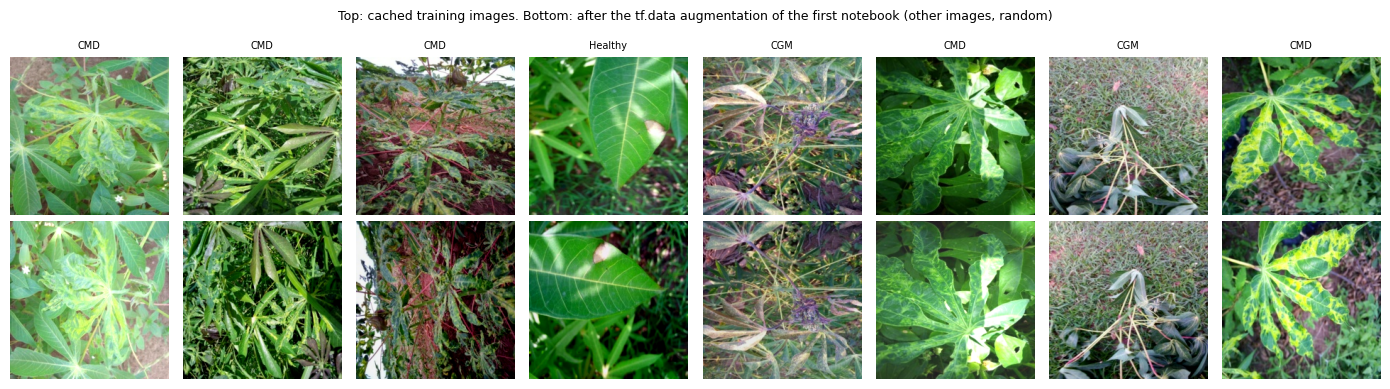

In [13]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.ensure_shape(img, [IMG_SIZE, IMG_SIZE, 3])
    return tf.cast(img, tf.float32), label

def tfdata_augment(img, label):
    """Augmentation of the first notebook, applied inside the tf.data pipeline (pixels are 0-255 here,
    so the brightness step 0.15 on a 0-1 scale becomes 0.15 * 255)."""
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.15 * 255)
    img = tf.image.random_contrast(img, 0.85, 1.15)
    img = tf.image.rot90(img, tf.random.uniform([], 0, 4, dtype=tf.int32))
    return tf.clip_by_value(img, 0.0, 255.0), label

def make_ds(df, shuffle=False, batch_size=BATCH_SIZE, augment_fn=None):
    ds = tf.data.Dataset.from_tensor_slices((df.filepath.values, df.label.values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if augment_fn is not None:
        ds = ds.map(augment_fn, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds      = make_ds(train_df, shuffle=True)
train_eval_ds = make_ds(train_df)           # same data, no shuffling: used to measure training metrics at the end
val_ds, test_ds = make_ds(val_df), make_ds(test_df)

xb, yb = next(iter(make_ds(train_df, shuffle=True, batch_size=8)))
print("batch:", xb.shape, xb.dtype, "| pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))
xa, _ = next(iter(make_ds(train_df, shuffle=True, batch_size=8, augment_fn=tfdata_augment)))   # augmentation of the first notebook
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(xb[i].numpy().astype("uint8")); axes[0, i].set_title(SHORT_NAMES[int(yb[i])], fontsize=7); axes[0, i].axis("off")
    axes[1, i].imshow(xa[i].numpy().astype("uint8")); axes[1, i].axis("off")
axes[0, 0].set_ylabel("original"); fig.suptitle("Top: cached training images. Bottom: after the tf.data augmentation of the first notebook (other images, random)", fontsize=9)
plt.tight_layout(); plt.show()

### 7.2 Model definitions

* **Custom CNN (Sequential API):** blocks of two `Conv-BatchNorm-ReLU` layers and max-pooling, global average pooling and a dense head. The **first notebook's model** has three blocks (32, 64, 128 filters) and one dropout layer after the dense layer; the controlled series from experiment 2 onwards uses four blocks (32-256 filters). Both show what a network trained **from scratch** can do.
* **Transfer learning (Functional API):** an ImageNet-pretrained **MobileNetV2** or **EfficientNetB0** backbone with a new softmax head. Backbone BatchNorm layers stay frozen. For fine-tuning, the head is first trained alone for a few *warm-up* epochs, then the last *n* backbone layers are unfrozen with a small learning rate.

Every experiment is a configuration dictionary, so each run differs from its parent in documented ways only.

In [14]:
def build_augmentation():
    return keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.15),
                             layers.RandomZoom(0.10), layers.RandomContrast(0.15),
                             layers.RandomBrightness(0.15, value_range=(0, 255))], name="augmentation")

def build_custom_cnn(cfg):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    m = keras.Sequential(name=cfg["run_name"])
    m.add(layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    if cfg["augment"]:
        m.add(build_augmentation())
    m.add(layers.Rescaling(1 / 255.0))
    for f in cfg["filters"]:
        for _ in range(2):
            m.add(layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_regularizer=reg))
            m.add(layers.BatchNormalization()); m.add(layers.ReLU())
        m.add(layers.MaxPooling2D(2))
    m.add(layers.GlobalAveragePooling2D())
    if cfg["dropout"] > 0 and not cfg["single_dropout"]: m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(128, activation="relu", kernel_regularizer=reg))
    if cfg["dropout"] > 0: m.add(layers.Dropout(cfg["dropout"]))      # the first notebook used this single dropout
    m.add(layers.Dense(N_CLASSES, activation="softmax"))
    return m, None

def build_transfer(cfg):
    reg = regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None
    weights = "imagenet" if USE_PRETRAINED else None
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = build_augmentation()(inputs) if cfg["augment"] else inputs
    if cfg["arch"] == "mobilenetv2":
        base = MobileNetV2(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
        x = layers.Rescaling(1 / 127.5, offset=-1)(x)          # MobileNetV2 expects [-1, 1]
    else:
        base = EfficientNetB0(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))   # expects 0-255, rescales inside
    x = base(x, training=False)                                  # BatchNorm layers stay in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    if cfg["dropout"] > 0: x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", kernel_regularizer=reg, name="prediction")(x)
    return keras.Model(inputs, outputs, name=cfg["run_name"]), base

def build_model(cfg):
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    return build_custom_cnn(cfg) if cfg["arch"] == "custom_cnn" else build_transfer(cfg)

def set_trainable(base, n_unfreeze):
    if base is None: return
    if n_unfreeze == 0:
        base.trainable = False; return
    base.trainable = True
    for l in base.layers[:-n_unfreeze]: l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization): l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=3, name="top3_acc")])

for arch in ("custom_cnn", "mobilenetv2"):
    m, _ = build_model(dict(run_name="summary_check", arch=arch, augment=True, dropout=0.3, l2=0.0, filters=(32, 64, 128, 256), single_dropout=False))
    print(f"{arch}: {m.count_params() / 1e6:.2f}M parameters")

custom_cnn: 1.21M parameters
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
mobilenetv2: 2.26M parameters


### 7.3 Experiment design

Nine deep-learning experiments were run. Experiment 1 reproduces the original notebook configuration; experiments 2–9 form a sequence in which each run changes selected design choices.

| # | Run | Change from its parent | Question it answers |
|---|---|---|---|
| 1 | `dl_exp_01_cnn3_first_notebook` | original design: 3-block CNN, tf.data augmentation, dropout 0.4, patience 7, LR halving, 30 epochs | what did the original design achieve on the full data? |
| 2 | `dl_exp_02_cnn4_baseline` | Four-block CNN (32–256 filters), Adam 1e-3, class weights, no augmentation or dropout | What does a plain CNN trained from scratch achieve? |
| 3 | `dl_exp_03_cnn4_augmentation` | Added augmentation layers to experiment 2 | Did augmentation improve generalisation? |
| 4 | `dl_exp_04_cnn4_dropout_l2` | Added dropout 0.4 and L2 regularisation 1e-4 to experiment 3 | Did additional regularisation help? |
| 5 | `dl_exp_05_cnn4_lr_3e-4` | Reduced learning rate to 3e-4 and added ReduceLROnPlateau | Did a lower learning rate improve training? |
| 6 | `dl_exp_06_mobilenetv2_frozen` | Replaced the custom CNN with a frozen ImageNet-pretrained MobileNetV2 backbone and a new head | How useful are pretrained features without fine-tuning? |
| 7 | `dl_exp_07_mobilenetv2_finetune40` | Unfroze the last 40 MobileNetV2 layers, using a lower learning rate and three warm-up epochs | Did fine-tuning improve performance? |
| 8 | `dl_exp_08_efficientnetb0_finetune40` | Used EfficientNetB0 with a comparable fine-tuning recipe | Did the alternative pretrained backbone help? |
| 9 | `dl_exp_09_effnet_no_class_weights` | Removed class weights from experiment 8 | How did class weighting affect the results? |

Images were resized and cached once, exact duplicates were removed, and all retained images were split consistently. Experiments 3–5 stopped after 8–9 epochs with early-stopping patience 4, while experiment 1 used patience 7; therefore, comparisons between these runs are tentative because the stopping rules differed. Re-running experiments 3–5 with a matched patience setting would provide a fairer comparison.


In [15]:
def E(n): return max(1, int(round(n * EPOCH_SCALE))) if not QUICK_RUN else 1

DEFAULT = dict(arch="custom_cnn", lr=1e-3, epochs=E(25), batch_size=BATCH_SIZE, augment=False, dropout=0.0, l2=0.0,
               unfreeze=0, warmup=0, reduce_lr=False, class_weights=True,
               filters=(32, 64, 128, 256), single_dropout=False, tfdata_aug=False,
               patience=4, rlr_factor=0.3, rlr_patience=2, min_lr=1e-7)
def exp(parent, run_name, **changes): return {**parent, **changes, "run_name": run_name}

# Experiment 1 = the first notebook, unchanged (3 blocks, tf.data augmentation, dropout 0.4, patience 7, LR x0.5 after 4 epochs, 30 epochs)
d1 = exp(DEFAULT, "dl_exp_01_cnn3_first_notebook", filters=(32, 64, 128), single_dropout=True, dropout=0.4, tfdata_aug=True,
         epochs=E(30), patience=7, reduce_lr=True, rlr_factor=0.5, rlr_patience=4, min_lr=1e-6)
# Experiments 2-9 = controlled series
d2 = exp(DEFAULT, "dl_exp_02_cnn4_baseline")
d3 = exp(d2, "dl_exp_03_cnn4_augmentation", augment=True)
d4 = exp(d3, "dl_exp_04_cnn4_dropout_l2", dropout=0.4, l2=1e-4)
d5 = exp(d4, "dl_exp_05_cnn4_lr_3e-4", lr=3e-4, reduce_lr=True)
d6 = exp(d4, "dl_exp_06_mobilenetv2_frozen", arch="mobilenetv2", dropout=0.3, l2=0.0, epochs=E(15))
d7 = exp(d6, "dl_exp_07_mobilenetv2_finetune40", unfreeze=40, lr=1e-4, warmup=3, epochs=E(15), reduce_lr=True)
d8 = exp(d7, "dl_exp_08_efficientnetb0_finetune40", arch="efficientnetb0")
d9 = exp(d8, "dl_exp_09_effnet_no_class_weights", class_weights=False)
DL_EXPERIMENTS = [d1, d2, d3, d4, d5, d6, d7, d8, d9]
display(pd.DataFrame(DL_EXPERIMENTS).set_index("run_name"))

,arch,lr,epochs,batch_size,augment,dropout,l2,unfreeze,warmup,reduce_lr,class_weights,filters,single_dropout,tfdata_aug,patience,rlr_factor,rlr_patience,min_lr
run_name,,,,,,,,,,,,,,,,,,
dl_exp_01_cnn3_first_notebook,custom_cnn,0.0010,30,32,False,0.4,0.0000,0,0,True,True,"(32, 64, 128)",True,True,7,0.5,4,1.000000e-06
dl_exp_02_cnn4_baseline,custom_cnn,0.0010,25,32,False,0.0,0.0000,0,0,False,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_03_cnn4_augmentation,custom_cnn,0.0010,25,32,True,0.0,0.0000,0,0,False,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_04_cnn4_dropout_l2,custom_cnn,0.0010,25,32,True,0.4,0.0001,0,0,False,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_05_cnn4_lr_3e-4,custom_cnn,0.0003,25,32,True,0.4,0.0001,0,0,True,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_06_mobilenetv2_frozen,mobilenetv2,0.0010,15,32,True,0.3,0.0000,0,0,False,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_07_mobilenetv2_finetune40,mobilenetv2,0.0001,15,32,True,0.3,0.0000,40,3,True,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_08_efficientnetb0_finetune40,efficientnetb0,0.0001,15,32,True,0.3,0.0000,40,3,True,True,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07
dl_exp_09_effnet_no_class_weights,efficientnetb0,0.0001,15,32,True,0.3,0.0000,40,3,True,False,"(32, 64, 128, 256)",False,False,4,0.3,2,1.000000e-07


In [16]:
def run_dl(cfg):
    name = cfg["run_name"]
    if done(name):
        print("skip (already done):", name); return
    t0 = time.time()
    log_dir = os.path.join(LOG_ROOT, name); shutil.rmtree(log_dir, ignore_errors=True)
    model, base = build_model(cfg)
    hparams = dict(paradigm=DT, arch=cfg["arch"], lr=cfg["lr"], epochs=cfg["epochs"], batch_size=cfg["batch_size"],
                   augment=cfg["augment"], dropout=cfg["dropout"], l2=cfg["l2"], unfrozen_layers=cfg["unfreeze"],
                   warmup_epochs=cfg["warmup"], class_weights=cfg["class_weights"], reduce_lr=cfg["reduce_lr"], seed=SEED,
                   filters=cfg["filters"], tfdata_aug=cfg["tfdata_aug"], patience=cfg["patience"])
    cw = CLASS_WEIGHTS if cfg["class_weights"] else None
    ds = make_ds(train_df, shuffle=True, batch_size=cfg["batch_size"], augment_fn=tfdata_augment if cfg["tfdata_aug"] else None)

    def callbacks(stop=True):
        cbs = [keras.callbacks.TensorBoard(log_dir=log_dir), hp.KerasCallback(log_dir, flat(hparams))]
        if stop:
            cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg["patience"], restore_best_weights=True))
            if cfg["reduce_lr"]:
                cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=cfg["rlr_factor"], patience=cfg["rlr_patience"], min_lr=cfg["min_lr"]))
        return cbs

    hist = {}
    def merge(h):
        for k, v in h.history.items(): hist.setdefault(k, []).extend([float(x) for x in v])

    start = 0
    if cfg["warmup"] > 0:                                   # stage A: new head only
        set_trainable(base, 0); compile_model(model, 1e-3)
        merge(model.fit(ds, validation_data=val_ds, epochs=cfg["warmup"], class_weight=cw, callbacks=callbacks(stop=False), verbose=2))
        start = cfg["warmup"]
    if cfg["arch"] != "custom_cnn":
        set_trainable(base, cfg["unfreeze"])
    compile_model(model, cfg["lr"])
    total = max(cfg["epochs"], start + 1)
    merge(model.fit(ds, validation_data=val_ds, epochs=total, initial_epoch=start, class_weight=cw, callbacks=callbacks(), verbose=2))

    model.save(f"{MODEL_DIR}/{name}.keras")
    probs = dict(train=model.predict(train_eval_ds, verbose=0), val=model.predict(val_ds, verbose=0), test=model.predict(test_ds, verbose=0))
    hist["best_epoch"] = int(np.argmin(hist["val_loss"])) + 1; hist["warmup"] = cfg["warmup"]
    HISTORIES[name] = hist
    json.dump(hist, open(f"{HIST_DIR}/{name}.json", "w"))
    log_run(name, DT, cfg["arch"], hparams, probs, log_dir, notes=f"best epoch {hist['best_epoch']}/{len(hist['loss'])}")
    print(f"   {(time.time() - t0) / 60:.1f} min")

for cfg in DL_EXPERIMENTS:
    run_dl(cfg)

Epoch 1/30
469/469 - 122s - 261ms/step - accuracy: 0.3662 - loss: 1.5529 - top3_acc: 0.7408 - val_accuracy: 0.0530 - val_loss: 3.7948 - val_top3_acc: 0.2745 - learning_rate: 0.0010
Epoch 2/30
469/469 - 83s - 176ms/step - accuracy: 0.4518 - loss: 1.4324 - top3_acc: 0.8052 - val_accuracy: 0.5178 - val_loss: 1.3990 - val_top3_acc: 0.8025 - learning_rate: 0.0010
Epoch 3/30
469/469 - 82s - 176ms/step - accuracy: 0.4719 - loss: 1.4003 - top3_acc: 0.8209 - val_accuracy: 0.1022 - val_loss: 1.7624 - val_top3_acc: 0.4016 - learning_rate: 0.0010
Epoch 4/30
469/469 - 83s - 176ms/step - accuracy: 0.4948 - loss: 1.3632 - top3_acc: 0.8372 - val_accuracy: 0.5340 - val_loss: 1.1350 - val_top3_acc: 0.8975 - learning_rate: 0.0010
Epoch 5/30
469/469 - 82s - 174ms/step - accuracy: 0.5196 - loss: 1.3064 - top3_acc: 0.8565 - val_accuracy: 0.6234 - val_loss: 1.3505 - val_top3_acc: 0.8826 - learning_rate: 0.0010
Epoch 6/30
469/469 - 82s - 176ms/step - accuracy: 0.5727 - loss: 1.2359 - top3_acc: 0.8797 - val_ac

### Interpretation of Deep-Learning Experiments

The original three-block CNN achieved validation macro-F1 of 0.6645, while the four-block baseline achieved 0.5798. Validation macro-F1 fell to 0.4309 with augmentation, 0.2473 after adding dropout and L2, and recovered only to 0.3738 after lowering the learning rate. These results show that the tested configurations did not improve on the original CNN; they do not establish that augmentation or regularisation is generally ineffective.

Experiments 3–5 stopped after 8–9 epochs with patience 4, whereas experiment 1 used patience 7, so these comparisons are tentative. Freezing MobileNetV2 achieved validation macro-F1 of 0.4851, and fine-tuning improved it to 0.6347. EfficientNetB0 fine-tuning achieved 0.6474; removing class weights raised validation macro-F1 to 0.6678 and test macro-F1 to 0.6915, the strongest test result in these experiments.


,run_name,paradigm,train_macro_f1,val_macro_f1,gap_macro_f1,val_balanced_accuracy,test_macro_f1,test_accuracy,test_roc_auc_ovr,diagnosis,notes
0,trad_exp_01_logreg_color,traditional ML,0.3372,0.3257,0.0115,0.3860,0.3096,0.4034,0.6883,high bias (underfitting),"baseline, colour features only"
1,trad_exp_02_rf_color,traditional ML,1.0000,0.2257,0.7743,0.2403,0.2127,0.6255,0.7333,high variance (overfitting),"non-linear model, same features"
2,trad_exp_03_rf_color_domain_texture,traditional ML,1.0000,0.2793,0.7207,0.2742,0.2706,0.6417,0.7753,high variance (overfitting),+ domain and texture features
3,trad_exp_04_rf_all_with_hog,traditional ML,1.0000,0.1523,0.8477,0.2000,0.1523,0.6150,0.7227,high variance (overfitting),+ HOG features
4,trad_exp_05_logreg_tuned,traditional ML,0.4149,0.3997,0.0152,0.4530,0.3959,0.5050,0.7665,high bias (underfitting),tuned C
5,trad_exp_06_svm_rbf_tuned,traditional ML,0.8087,0.4024,0.4063,0.3764,0.3749,0.6595,0.8162,high variance (overfitting),tuned C and gamma
6,trad_exp_07_hgb_tuned,traditional ML,0.7660,0.4284,0.3376,0.4578,0.4162,0.5745,0.7879,high variance (overfitting),"gradient boosting, tuned"
7,trad_exp_08_rf_tuned,traditional ML,0.7254,0.4080,0.3174,0.4353,0.3945,0.5483,0.7467,high variance (overfitting),"random forest, tuned"
8,dl_exp_01_cnn3_first_notebook,deep learning,0.6887,0.6645,0.0242,0.6860,0.6747,0.8031,0.9426,balanced,best epoch 23/30
9,dl_exp_02_cnn4_baseline,deep learning,0.6195,0.5798,0.0397,0.5466,0.5939,0.7632,0.9152,balanced,best epoch 12/16


17 experiments: 8 traditional, 9 deep learning


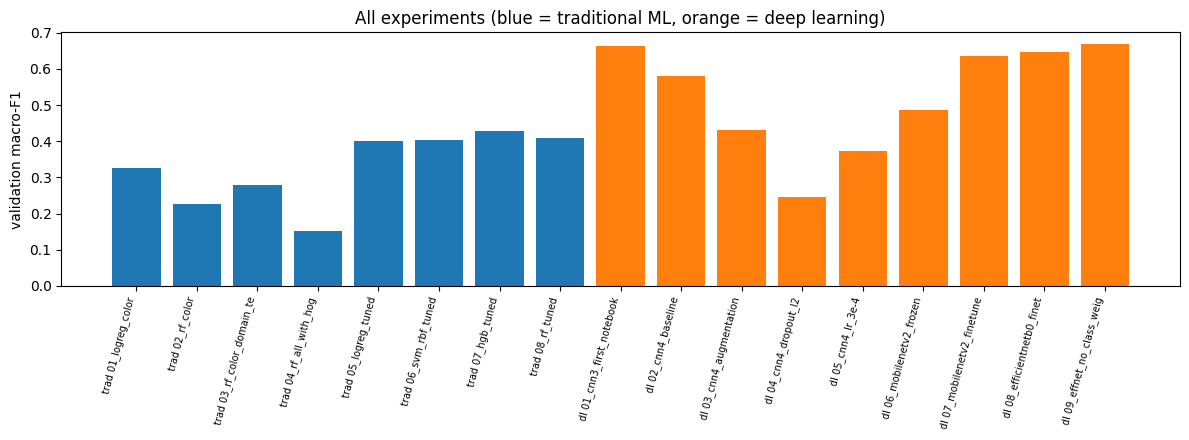

In [17]:
for p in glob.glob(f"{HIST_DIR}/*.json"):
    HISTORIES.setdefault(os.path.basename(p)[:-5], json.load(open(p)))
res = pd.DataFrame(RESULTS)
UNDERFIT_F1, OVERFIT_GAP = 0.60, 0.10
def diagnose(r):
    if r.train_macro_f1 < UNDERFIT_F1: return "high bias (underfitting)"
    if r.gap_macro_f1 > OVERFIT_GAP:   return "high variance (overfitting)"
    return "balanced"
res["diagnosis"] = res.apply(diagnose, axis=1)
cols = ["run_name", "paradigm", "train_macro_f1", "val_macro_f1", "gap_macro_f1", "val_balanced_accuracy",
        "test_macro_f1", "test_accuracy", "test_roc_auc_ovr", "diagnosis", "notes"]
display(res[cols].style.format({c: "{:.4f}" for c in cols[2:9]}).background_gradient(subset=["val_macro_f1"], cmap="Greens"))
print(f"{len(res)} experiments: {int((res.paradigm == TR).sum())} traditional, {int((res.paradigm == DT).sum())} deep learning")

fig, ax = plt.subplots(figsize=(12, 4.5))
colors = res.paradigm.map({TR: "tab:blue", DT: "tab:orange"})
ax.bar(range(len(res)), res.val_macro_f1, color=colors)
ax.set_xticks(range(len(res))); ax.set_xticklabels([r.replace("_exp_", " ")[:26] for r in res.run_name], rotation=75, ha="right", fontsize=7)
ax.set_ylabel("validation macro-F1"); ax.set_title("All experiments (blue = traditional ML, orange = deep learning)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/all_experiments.png", dpi=150); plt.show()

### Interpretation of the Experiment Comparison Table

The table contains **17 experiments: 8 traditional ML runs and 9 deep-learning runs**. The strongest model should be selected using validation macro-F1, while test metrics are reserved for the final comparison. The recorded results identify `dl_exp_09_effnet_no_class_weights` (EfficientNetB0 without class weights) as the strongest deep-learning run, and `trad_exp_07_hgb_tuned` (HistGradientBoosting) as the strongest traditional run.

The train–validation macro-F1 gap helps diagnose generalisation. A small gap means training and validation scores are similar, although both could still be low (underfitting). A large positive gap means training performance is much higher than validation performance, which is evidence of overfitting. Interpret this alongside the absolute scores and learning curves rather than treating the gap as a definitive diagnosis on its own.

The experiments also show that a change does not automatically improve results: augmentation and dropout/L2 reduced validation macro-F1 in the tested custom-CNN configurations, while fine-tuning improved MobileNetV2 compared with keeping its backbone frozen. The best outcome depends on the model and training setup.


### Comparison of Traditional ML and Deep Learning

**Ranking:** Deep learning performed best. EfficientNetB0 without class weights achieved the highest test macro-F1 (0.6915), followed by the initial CNN (0.6747). HistGradientBoosting was the best traditional model (0.4162).

**Architecture and hyperparameters:** Traditional models used handcrafted colour, texture, domain and HOG features. Deep learning used CNNs and pretrained MobileNetV2/EfficientNetB0. Fine-tuning improved transfer-learning results, while removing class weights improved EfficientNetB0 performance.

**Bias and variance:** Logistic Regression and several regularised CNN experiments showed high bias. Random Forest, SVM and HistGradientBoosting showed overfitting, as did fine-tuned EfficientNetB0. We experimented with tuning, augmentation, dropout, L2 regularisation and transfer learning to improve generalisation.

**Training cost:** Traditional models generally trained faster, while CNNs required more computation. Transfer learning achieved better performance, but a complete accuracy–cost comparison requires recorded training times and model sizes.


In [18]:
def best_run(paradigm):
    r = res[res.paradigm == paradigm].sort_values("val_macro_f1")
    return r.iloc[-1].run_name
BEST = {TR: best_run(TR), DT: best_run(DT)}
print("Best traditional:", BEST[TR], "\nBest deep learning:", BEST[DT])
TEST_PROBS = {p: np.load(f"{PRED_DIR}/{n}.npz")["test"] for p, n in BEST.items()}
summary = pd.DataFrame({p: evaluate_probs(y_test, TEST_PROBS[p])[0] for p in BEST}).T
summary.insert(0, "run", [BEST[p] for p in summary.index]); display(summary.style.format({c: "{:.4f}" for c in summary.columns[1:]}))

def report(name, probs):
    _, pred = evaluate_probs(y_test, probs)
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=SHORT_NAMES, digits=3, zero_division=0))
for p in BEST: report(BEST[p], TEST_PROBS[p])

Best traditional: trad_exp_07_hgb_tuned 
Best deep learning: dl_exp_09_effnet_no_class_weights


,run,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc_ovr,log_loss
traditional ML,trad_exp_07_hgb_tuned,0.5745,0.4422,0.4028,0.4422,0.4162,0.5954,0.7879,1.1042
deep learning,dl_exp_09_effnet_no_class_weights,0.8221,0.6732,0.7218,0.6732,0.6915,0.8187,0.9446,0.5129


===== trad_exp_07_hgb_tuned =====
              precision    recall  f1-score   support

         CBB      0.240     0.387     0.296       163
        CBSD      0.297     0.362     0.326       329
         CGM      0.286     0.369     0.322       358
         CMD      0.827     0.698     0.757      1974
     Healthy      0.364     0.396     0.380       386

    accuracy                          0.574      3210
   macro avg      0.403     0.442     0.416      3210
weighted avg      0.627     0.574     0.595      3210

===== dl_exp_09_effnet_no_class_weights =====
              precision    recall  f1-score   support

         CBB      0.639     0.466     0.539       163
        CBSD      0.748     0.578     0.652       329
         CGM      0.717     0.673     0.695       358
         CMD      0.910     0.942     0.926      1974
     Healthy      0.595     0.707     0.646       386

    accuracy                          0.822      3210
   macro avg      0.722     0.673     0.691      32

### Interpretation of the Best-Model Evaluation

On the held-out test set, EfficientNetB0 achieved **macro-F1 = 0.691**, **accuracy = 0.822**, and **macro-average F1 = 0.691** in the classification report. The best traditional model, HistGradientBoosting, achieved test macro-F1 of **0.416**. This is a substantial improvement in balanced class performance for EfficientNetB0.

EfficientNetB0 performed best on CMD (F1 = 0.926, recall = 0.942), the majority class. It also performed reasonably on CGM (F1 = 0.695) and CBSD (F1 = 0.652), but CBB remained more difficult (F1 = 0.539, recall = 0.466). Healthy-class F1 was 0.646. Therefore, the overall score should not hide the weaker performance on less frequent classes.


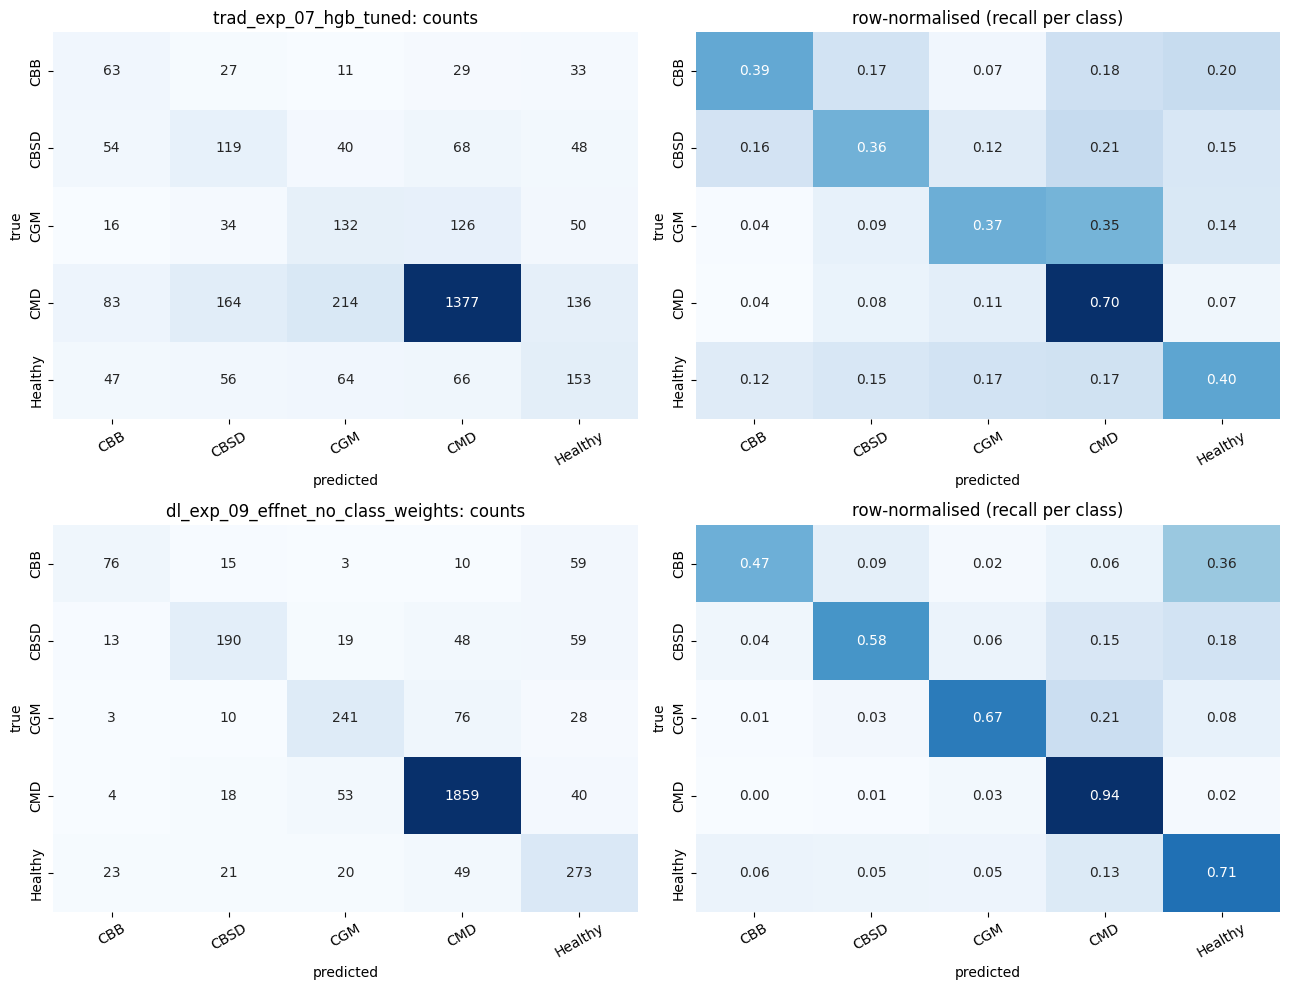

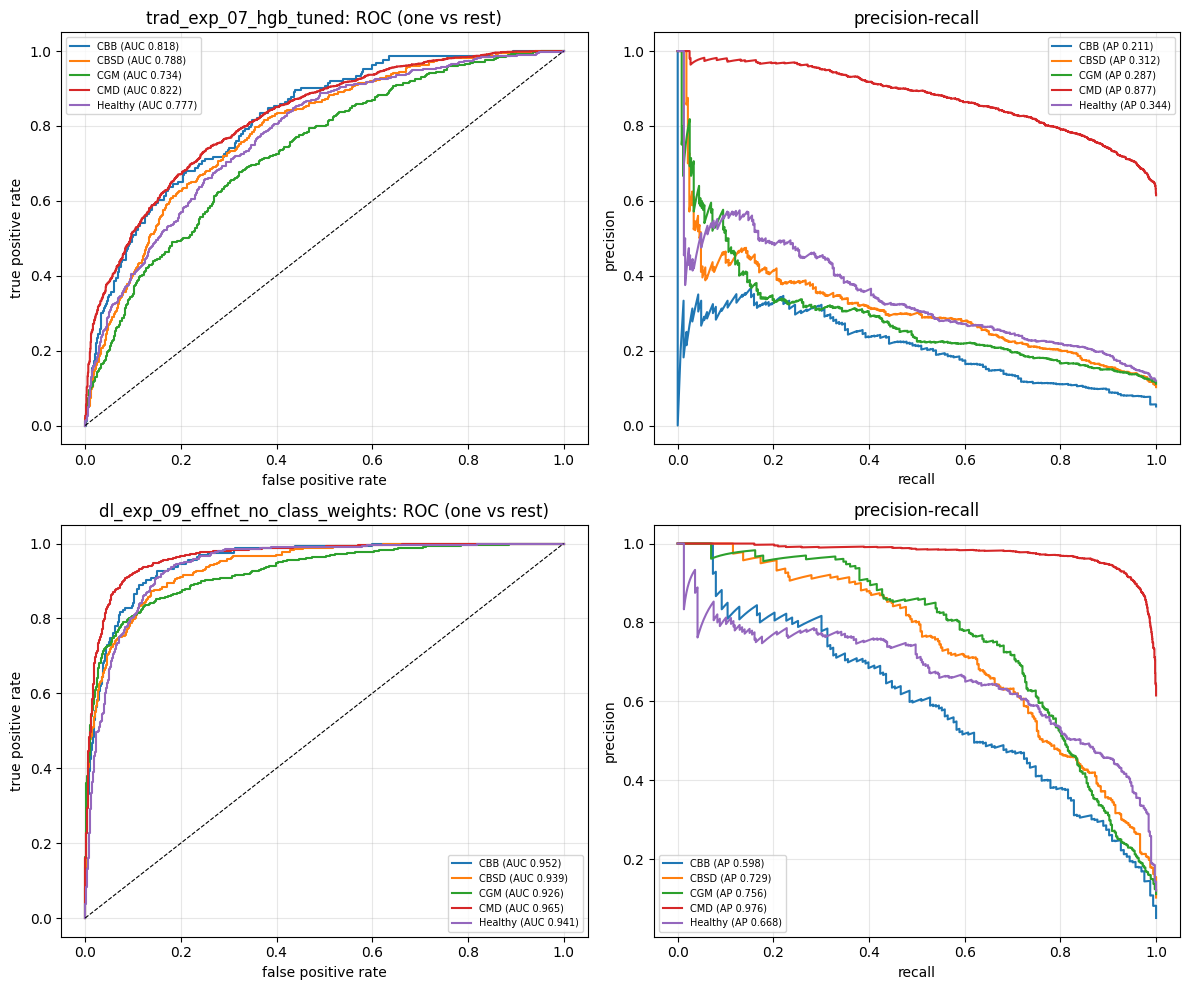

In [19]:
def plot_confusions(items):
    fig, axes = plt.subplots(len(items), 2, figsize=(13, 5 * len(items)))
    axes = np.atleast_2d(axes)
    for r, (name, probs) in enumerate(items):
        pred = probs.argmax(1); cm = confusion_matrix(y_test, pred, labels=range(N_CLASSES))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[r, 0], xticklabels=SHORT_NAMES, yticklabels=SHORT_NAMES, cbar=False)
        sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", ax=axes[r, 1], xticklabels=SHORT_NAMES, yticklabels=SHORT_NAMES, cbar=False)
        axes[r, 0].set_title(f"{name}: counts"); axes[r, 1].set_title("row-normalised (recall per class)")
        for a in axes[r]: a.set_xlabel("predicted"); a.set_ylabel("true"); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=150); plt.show()

def plot_roc_pr(items):
    Y = label_binarize(y_test, classes=range(N_CLASSES))
    fig, axes = plt.subplots(len(items), 2, figsize=(12, 5 * len(items)))
    axes = np.atleast_2d(axes)
    for r, (name, probs) in enumerate(items):
        for c in range(N_CLASSES):
            fpr, tpr, _ = roc_curve(Y[:, c], probs[:, c]); axes[r, 0].plot(fpr, tpr, label=f"{SHORT_NAMES[c]} (AUC {roc_auc_score(Y[:, c], probs[:, c]):.3f})")
            pr, rc, _ = precision_recall_curve(Y[:, c], probs[:, c]); axes[r, 1].plot(rc, pr, label=f"{SHORT_NAMES[c]} (AP {average_precision_score(Y[:, c], probs[:, c]):.3f})")
        axes[r, 0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[r, 0].set_title(f"{name}: ROC (one vs rest)"); axes[r, 0].set_xlabel("false positive rate"); axes[r, 0].set_ylabel("true positive rate")
        axes[r, 1].set_title("precision-recall"); axes[r, 1].set_xlabel("recall"); axes[r, 1].set_ylabel("precision")
        for a in axes[r]: a.legend(fontsize=7); a.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/roc_pr_curves.png", dpi=150); plt.show()

ITEMS = [(BEST[p], TEST_PROBS[p]) for p in (TR, DT)]
plot_confusions(ITEMS); plot_roc_pr(ITEMS)

### Interpretation of the Confusion Matrices

The confusion matrices compare HistGradientBoosting with EfficientNetB0; the diagonal cells are correct predictions, and off-diagonal cells show errors. EfficientNetB0 correctly classified **1,859 of 1,974 CMD images** (recall 0.94), compared with 1,377 CMD images for HistGradientBoosting (recall 0.70). EfficientNetB0 also improved recall for CBB (0.47 vs 0.39), CBSD (0.58 vs 0.36), CGM (0.67 vs 0.37), and Healthy (0.71 vs 0.40). However, CBB was still often predicted as Healthy (59 images), and CGM was often predicted as CMD (76 images).


### Interpretation of the ROC Curves

The ROC curves show the trade-off between true-positive rate and false-positive rate for each class in a one-versus-rest comparison. EfficientNetB0 had higher AUC for all five classes (0.926–0.965) than HistGradientBoosting (0.734–0.822), and its macro ROC-AUC was **0.9446** compared with **0.7879** for HistGradientBoosting. The EfficientNetB0 curves stay closer to the top-left corner, indicating better separation between each class and the remaining classes. ROC-AUC is useful for ranking predictions, but it should be read alongside the confusion matrix and PR curves because class frequencies are imbalanced.


### Interpretation of the Precision–Recall Curves

The precision–recall curves are especially informative for this imbalanced dataset because they show how precision changes as recall increases. EfficientNetB0 achieved average precision of **0.976 for CMD**, but lower values for CBB (0.598), Healthy (0.668), CBSD (0.729), and CGM (0.756); HistGradientBoosting's values were lower for every class, including 0.877 for CMD and 0.211 for CBB. The weaker CBB curve indicates that identifying this minority class remains difficult, even though EfficientNetB0 improved substantially over the traditional model. These curves support the class-specific findings from the confusion matrices rather than relying on overall accuracy alone.


### 9.1 Learning curves

The plots below compare training and validation loss/accuracy for the best deep-learning model and training versus cross-validation macro-F1 for the best traditional model. The dashed vertical line on the deep-learning plots marks the epoch whose weights were restored by early stopping; the dotted line marks the end of warm-up. The traditional learning curve shows how performance changes as more training examples are used.


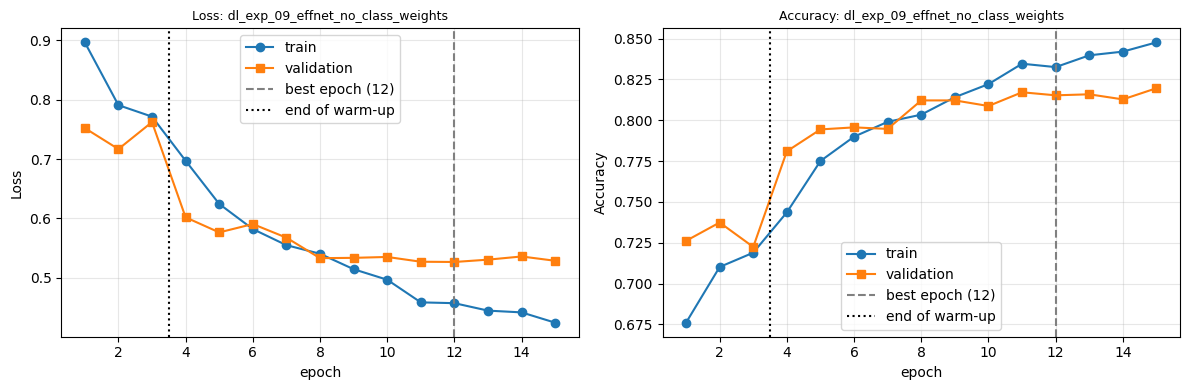

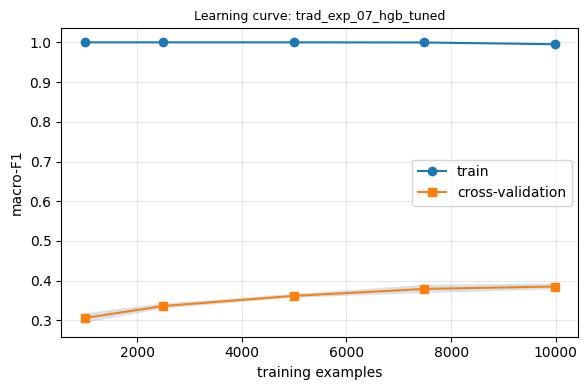

In [20]:
def plot_history(name):
    h = HISTORIES[name]; ep = range(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("accuracy", "Accuracy")]):
        a.plot(ep, h[k], "o-", label="train"); a.plot(ep, h["val_" + k], "s-", label="validation")
        a.axvline(h["best_epoch"], ls="--", c="gray", label=f"best epoch ({h['best_epoch']})")
        if h.get("warmup"): a.axvline(h["warmup"] + 0.5, ls=":", c="k", label="end of warm-up")
        a.set_xlabel("epoch"); a.set_ylabel(t); a.set_title(f"{t}: {name}", fontsize=9); a.grid(alpha=0.3); a.legend()
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/learning_curve_{name}.png", dpi=150); plt.show()

def plot_sklearn_learning_curve(run_name):
    row = res[res.run_name == run_name].iloc[0]; hpar = json.loads(row.hparams)
    skip = {"paradigm", "model", "feature_set", "n_features", "tuned", "seed"}
    params = {k: v for k, v in hpar.items() if k not in skip}
    X = get_X("train", hpar["feature_set"])
    pipe = make_pipeline(hpar["model"], params, X.shape[1])
    sizes, tr, va = learning_curve(pipe, X, y_train, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], cv=2, scoring="f1_macro", n_jobs=1, random_state=SEED)
    plt.figure(figsize=(6, 4))
    plt.plot(sizes, tr.mean(1), "o-", label="train"); plt.plot(sizes, va.mean(1), "s-", label="cross-validation")
    plt.fill_between(sizes, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    plt.xlabel("training examples"); plt.ylabel("macro-F1"); plt.title(f"Learning curve: {run_name}", fontsize=9); plt.grid(alpha=0.3); plt.legend()
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/learning_curve_{run_name}.png", dpi=150); plt.show()

plot_history(BEST[DT])
plot_sklearn_learning_curve(BEST[TR])

### Interpretation of the Learning Curves

For EfficientNetB0, training loss continued to fall, while validation loss was lowest at **epoch 12** and then stayed nearly flat or rose slightly. Validation accuracy levelled off around **0.81–0.82**, while training accuracy continued to increase, indicating a modest train–validation gap and some late-stage overfitting. **Training ended at the 15-epoch limit**; the plot does not establish that early stopping restored epoch-12 weights. For HistGradientBoosting, training macro-F1 stayed close to 1.0 while cross-validation macro-F1 rose only from about **0.31 to 0.38** as more examples were added. This persistent gap suggests overfitting, and adding more training examples within this experiment did not close the gap substantially.

## 10. Error analysis

Which classes are systematically confused, and which images does the best model get wrong **with high confidence**? Confident mistakes are the interesting ones: they are either genuinely hard images, shortcuts the model has learned, or **wrong labels** (the Cassava labels are reported to be noisy, so examine them with that in mind).

Model analysed: dl_exp_09_effnet_no_class_weights


,count,true class,predicted as
0,76,CGM,CMD
1,59,CBSD,Healthy
2,59,CBB,Healthy
3,53,CMD,CGM
4,49,Healthy,CMD
5,48,CBSD,CMD


,support,recall,precision
CBB,163,0.466,0.639
CBSD,329,0.578,0.748
CGM,358,0.673,0.717
CMD,1974,0.942,0.910
Healthy,386,0.707,0.595


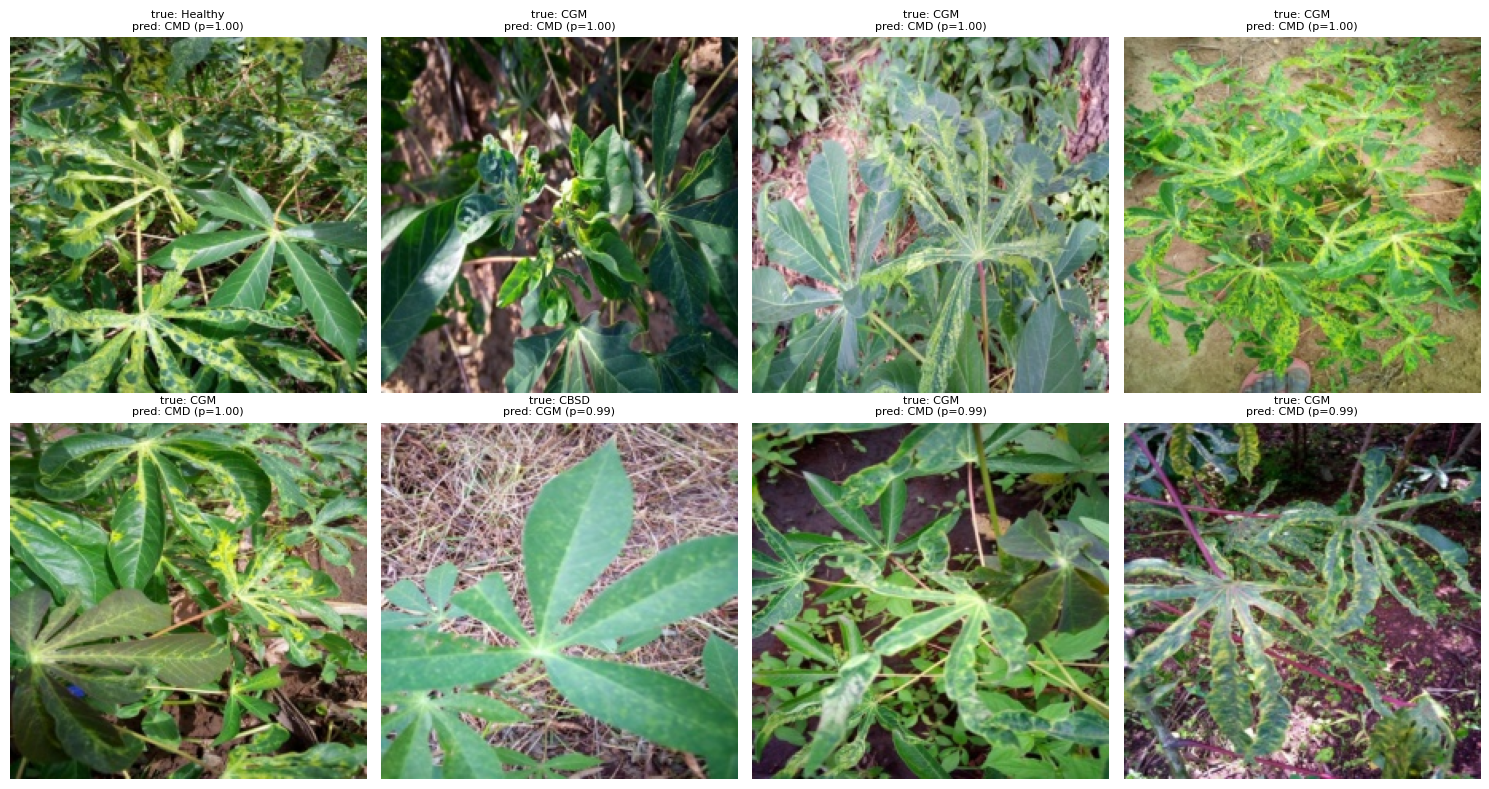

571 errors of 3210 test images; median confidence of the wrong predictions: 0.60


In [21]:
OVERALL_BEST = res.sort_values("val_macro_f1").iloc[-1].run_name
probs = np.load(f"{PRED_DIR}/{OVERALL_BEST}.npz")["test"]; pred = probs.argmax(1)
print("Model analysed:", OVERALL_BEST)
cm = confusion_matrix(y_test, pred, labels=range(N_CLASSES))
pairs = [(cm[i, j], SHORT_NAMES[i], SHORT_NAMES[j]) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j]
display(pd.DataFrame(sorted(pairs, reverse=True)[:6], columns=["count", "true class", "predicted as"]))

per_class = pd.DataFrame({"support": cm.sum(1), "recall": np.diag(cm) / cm.sum(1),
                          "precision": np.diag(cm) / np.maximum(cm.sum(0), 1)}, index=SHORT_NAMES)
display(per_class.round(3))

err = np.where(pred != y_test)[0]
conf = probs[err, pred[err]]
worst = err[np.argsort(-conf)][:8]
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for a, i in zip(axes.flat, worst):
    a.imshow(Image.open(test_df.filepath[i])); a.axis("off")
    a.set_title(f"true: {SHORT_NAMES[y_test[i]]}\npred: {SHORT_NAMES[pred[i]]} (p={probs[i, pred[i]]:.2f})", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/most_confident_errors.png", dpi=150); plt.show()
print(f"{len(err)} errors of {len(y_test)} test images" + (f"; median confidence of the wrong predictions: {np.median(conf):.2f}" if len(err) else ""))

### Interpretation of the Error Analysis

EfficientNetB0 made **571 incorrect predictions out of 3,210 test images**. Its most frequent confusions were CGM predicted as CMD (76 images), CBSD predicted as Healthy (59), and CBB predicted as Healthy (59). CMD recall was highest at **0.942**, while CBB recall was lowest at **0.466**, showing that the model is much more reliable for the majority CMD class than for CBB.

The eight high-confidence error examples include leaves labelled Healthy that were predicted as CMD, and several CGM images predicted as CMD. The images show varied lighting, backgrounds, overlapping foliage, and mottled green/yellow patterns that can make visual distinctions difficult; this inspection alone cannot confirm incorrect labels or shortcut learning. Useful next steps are to review suspicious labels, evaluate performance by class, and test the model on an independent dataset.


## 11. Saving the deliverables

Copies the best models into one folder for the Drive link (a `.joblib` file for traditional ML, a `.keras` file for deep learning), zips the TensorBoard logs and the engineered features. **Raw dataset:** the instructions ask for the zipped raw data in the Drive folder. Check the Kaggle competition rules on redistribution before sharing it publicly; set `COPY_RAW_ZIP = True` only if you are allowed to.

In [22]:
BEST_DIR = os.path.join(OUT_DIR, "best_models"); os.makedirs(BEST_DIR, exist_ok=True)
shutil.copy(f"{MODEL_DIR}/{BEST[TR]}.joblib", f"{BEST_DIR}/best_traditional_{BEST[TR]}.joblib")
shutil.copy(f"{MODEL_DIR}/{BEST[DT]}.keras",  f"{BEST_DIR}/best_deep_{BEST[DT]}.keras")
shutil.make_archive(f"{OUT_DIR}/tensorboard_logs", "zip", LOG_ROOT)
COPY_RAW_ZIP = False
if COPY_RAW_ZIP:
    shutil.copy(f"{BASE}/cassava-leaf-disease-classification.zip", f"{OUT_DIR}/cassava_raw_dataset.zip")
print(sorted(os.listdir(OUT_DIR)))
print(sorted(os.listdir(BEST_DIR)))

['best_models', 'figures', 'handcrafted_features_224.npz', 'histories', 'models', 'predictions', 'results_table.csv', 'split_manifest.csv', 'tensorboard', 'tensorboard_logs.zip']
['best_deep_dl_exp_09_effnet_no_class_weights.keras', 'best_traditional_trad_exp_07_hgb_tuned.joblib']


In [23]:
# Automated self-check against the project requirements
checks = {
    "at least 7 experiments in the table": len(res) >= 7,
    "at least 3 traditional and 3 deep-learning experiments": (res.paradigm == TR).sum() >= 3 and (res.paradigm == DT).sum() >= 3,
    "TensorBoard run for every experiment": all(os.path.isdir(os.path.join(LOG_ROOT, r)) for r in res.run_name),
    "best traditional model saved (.joblib)": any(f.endswith(".joblib") for f in os.listdir(BEST_DIR)),
    "best deep-learning model saved (.keras)": any(f.endswith(".keras") for f in os.listdir(BEST_DIR)),
    "results table saved": os.path.exists(RESULTS_CSV),
    "figures saved (confusion, ROC/PR, curves)": all(os.path.exists(f"{FIG_DIR}/{f}") for f in ("confusion_matrices.png", "roc_pr_curves.png")),
    "not a quick run": not QUICK_RUN,
}
for k, v in checks.items(): print("OK  " if v else "FAIL", k)

OK   at least 7 experiments in the table
OK   at least 3 traditional and 3 deep-learning experiments
OK   TensorBoard run for every experiment
OK   best traditional model saved (.joblib)
OK   best deep-learning model saved (.keras)
OK   results table saved
OK   figures saved (confusion, ROC/PR, curves)
OK   not a quick run


## 12. Conclusion, Limitations and Future Work

EfficientNetB0 without class weights was the best model, achieving a test macro-F1 of **0.6915**, accuracy of **0.8221**, and ROC-AUC of **0.9446**. The majority-class baseline, which always predicts CMD, achieves approximately 61.5% accuracy, so the best model performs substantially better. Deep learning justified its higher computational cost by outperforming traditional models, whose best test macro-F1 was 0.4162.

The main errors involved confusing CGM with CMD and predicting CBSD or CBB as Healthy. Limitations include class imbalance, possible label noise, one dataset source, field variations in lighting and backgrounds, resizing images to 224 × 224 pixels, and using one random seed and one data split.

Future work should include targeted augmentation for weaker classes, higher-resolution images, label cleaning, model ensembling, multiple random seeds with confidence intervals, and external validation on images from new fields.

**Reproducibility:** The experiments use seed 42, and the data split is saved in `split_manifest.csv`. Results are recorded in `results_table.csv`, with TensorBoard logs for each experiment. Python and library versions are documented in `requirements.txt`.